# 🏛️ Analytics Engineering: Modelado Dimensional (Kimball) & SQL Analítico Avanzado


En este proyecto asumimos el rol de **Analytics Engineer**:
1. Diseñamos un **Esquema Estrella (*Star Schema*)** bajo la metodología Kimball para estructurar datos transaccionales brutos de E-commerce.
2. Construimos un **Data Warehouse analítico embebido en DuckDB** capaz de ejecutar consultas vectorizadas en milisegundos.
3. Escribimos consultas analíticas de alto nivel en **SQL puro** (Window Functions, CTEs) para responder dos preguntas críticas de negocio:
   - **Análisis de Retención de Cohortes:** ¿Qué porcentaje de los clientes nuevos regresa a comprar en los meses 1, 2, 3...?
   - **Segmentación RFM (Recency, Frequency, Monetary):** ¿Quiénes son nuestros clientes Champions, Leales o en Riesgo de Abandono?


---
## 🔌 1. Conexión al Data Warehouse (DuckDB)
DuckDB funciona como una base de datos OLAP embebida: no requiere servidores externos ni clústeres, y procesa consultas analíticas columnares a velocidad de vértigo.


In [1]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Conectar al Data Warehouse en modo solo lectura
con = duckdb.connect("../data/warehouse/ecommerce_analytics.duckdb", read_only=True)

# Inspeccionar tablas en el esquema analítico
tables_df = con.execute("""
    SELECT 
        table_name,
        estimated_size AS total_rows
    FROM duckdb_tables()
    WHERE schema_name = 'main'
    ORDER BY table_name;
""").fetchdf()

display(tables_df)


,table_name,total_rows
0,dim_customers,1200
1,dim_date,1096
2,dim_products,24
3,fact_orders,4856


---
## 📐 2. Verificación del Esquema Estrella (Star Schema)
El modelo cuenta con una **Tabla de Hechos (`fact_orders`)** central y tres **Dimensiones (`dim_date`, `dim_customers`, `dim_products`)**.
- **Grano:** 1 fila = 1 artículo dentro de una orden de compra transaccional.
- **Claves Subrogadas (Surrogate Keys):** `customer_key`, `product_key`, `date_key`, `order_item_key`.


In [2]:
# Vista previa de la tabla de hechos con joins dimensionales enriquecidos
preview_sql = """
SELECT
    f.order_id,
    f.order_line_id,
    d.full_date,
    c.customer_name,
    c.country,
    c.segment AS customer_segment,
    p.product_name,
    p.category,
    f.quantity,
    f.unit_price,
    f.gross_amount,
    f.discount_amount,
    f.net_amount,
    f.margin_amount
FROM fact_orders f
JOIN dim_date d ON f.order_date_key = d.date_key
JOIN dim_customers c ON f.customer_key = c.customer_key
JOIN dim_products p ON f.product_key = p.product_key
LIMIT 5;
"""

display(con.execute(preview_sql).fetchdf())


,order_id,order_line_id,full_date,customer_name,country,customer_segment,product_name,category,quantity,unit_price,gross_amount,discount_amount,net_amount,margin_amount
0,ORD-10291,LINE-0000463,2023-01-01,Customer_114,México,Consumer,Notebook Leather Cover,Office Supplies,1,24.00,24.00,0.0,24.00,15.00
1,ORD-12125,LINE-0003521,2023-01-01,Customer_874,México,Consumer,Desk Pad Mat,Office Supplies,1,22.00,22.00,0.0,22.00,14.00
2,ORD-10152,LINE-0000249,2023-01-04,Customer_61,Perú,Consumer,Cable Management Box,Office Supplies,5,16.99,84.95,0.0,84.95,54.95
3,ORD-11383,LINE-0002302,2023-01-05,Customer_578,Colombia,Consumer,Thermal Coffee Mug,Apparel & Merch,1,25.00,25.00,2.5,22.50,12.50
4,ORD-11383,LINE-0002303,2023-01-05,Customer_578,Colombia,Consumer,Fountain Pen Set,Office Supplies,1,35.00,35.00,0.0,35.00,23.00


---
## 👥 3. Análisis de Cohortes de Retención (Retention Cohort Analysis)
### ¿Cómo funciona la consulta SQL?
1. **Identificar la Cohorte:** Se obtiene la primera fecha de compra (`MIN(order_month)`) para cada cliente.
2. **Calcular el `month_offset`:** Diferencia en meses entre la orden analizada y el mes de alta de la cohorte.
3. **Agrupación y Tasa (%):** Se calcula qué porcentaje de clientes activos en el Mes 0 sigue realizando órdenes en los meses 1, 2, 3...


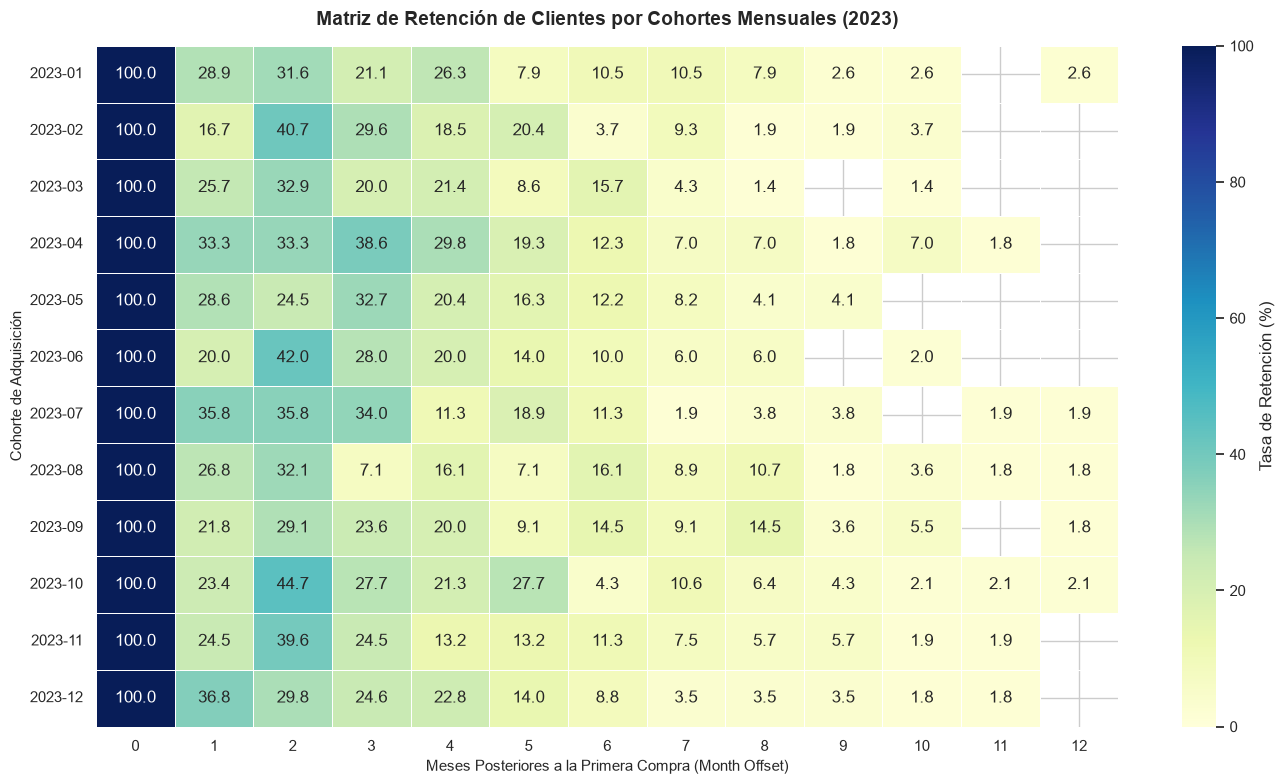

In [3]:
with_cohort_sql = """
WITH customer_orders AS (
    SELECT DISTINCT
        f.customer_key,
        DATE_TRUNC('month', d.full_date) AS order_month
    FROM fact_orders f
    JOIN dim_date d ON f.order_date_key = d.date_key
),
customer_first_purchase AS (
    SELECT
        customer_key,
        MIN(order_month) AS cohort_month
    FROM customer_orders
    GROUP BY customer_key
),
cohort_activity AS (
    SELECT
        co.customer_key,
        cfp.cohort_month,
        co.order_month,
        (CAST(EXTRACT('year' FROM co.order_month) AS INTEGER) - CAST(EXTRACT('year' FROM cfp.cohort_month) AS INTEGER)) * 12 +
        (CAST(EXTRACT('month' FROM co.order_month) AS INTEGER) - CAST(EXTRACT('month' FROM cfp.cohort_month) AS INTEGER)) AS period_number
    FROM customer_orders co
    JOIN customer_first_purchase cfp ON co.customer_key = cfp.customer_key
),
cohort_sizes AS (
    SELECT
        cohort_month,
        COUNT(DISTINCT customer_key) AS total_cohort_customers
    FROM cohort_activity
    WHERE period_number = 0
    GROUP BY cohort_month
)
SELECT
    strftime(ca.cohort_month, '%Y-%m') AS cohort,
    ca.period_number AS month_offset,
    ROUND(COUNT(DISTINCT ca.customer_key) * 100.0 / cs.total_cohort_customers, 1) AS retention_rate_pct
FROM cohort_activity ca
JOIN cohort_sizes cs ON ca.cohort_month = cs.cohort_month
WHERE ca.cohort_month >= '2023-01-01' AND ca.cohort_month <= '2023-12-01'
  AND ca.period_number <= 12
GROUP BY ca.cohort_month, cs.total_cohort_customers, ca.period_number
ORDER BY cohort, month_offset;
"""

df_cohorts = con.execute(with_cohort_sql).fetchdf()

# Pivotar datos para generar matriz (Cohortes en filas x Offset de meses en columnas)
cohort_matrix = df_cohorts.pivot(index='cohort', columns='month_offset', values='retention_rate_pct')

# Visualización Heatmap con Seaborn
plt.figure(figsize=(14, 8))
sns.heatmap(
    cohort_matrix, 
    annot=True, 
    fmt=".1f", 
    cmap="YlGnBu", 
    cbar_kws={'label': 'Tasa de Retención (%)'},
    vmin=0, 
    vmax=100,
    linewidths=0.5
)
plt.title("Matriz de Retención de Clientes por Cohortes Mensuales (2023)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Meses Posteriores a la Primera Compra (Month Offset)", fontsize=11)
plt.ylabel("Cohorte de Adquisición", fontsize=11)
plt.tight_layout()
plt.show()


---
## 💎 4. Segmentación RFM (Recency, Frequency, Monetary)
Utilizando la función de ventana `NTILE(4)`, categorizamos a cada cliente en 4 cuartiles para cada dimensión:
- **Recencia (R):** Días desde la última orden (menos días = mayor puntaje 4).
- **Frecuencia (F):** Número de órdenes completadas.
- **Valor Monetario (M):** Monto neto acumulado gastado en la plataforma.


,rfm_segment,total_customers,pct_customers,avg_recency,avg_orders,avg_spend,total_revenue,total_profit
0,Champions (Alto Valor),273,22.8,138.0,4.0,677.56,184973.67,94531.67
1,Clientes Leales,327,27.3,407.0,3.2,418.53,136857.72,70980.72
2,Ocasionales / Potenciales,212,17.7,245.0,1.6,290.78,61645.42,31727.42
3,Inactivos / Hibernando,267,22.3,490.0,1.2,101.18,27013.95,14900.95
4,Nuevos Prometedores,121,10.1,190.0,1.0,146.99,17785.22,9090.22


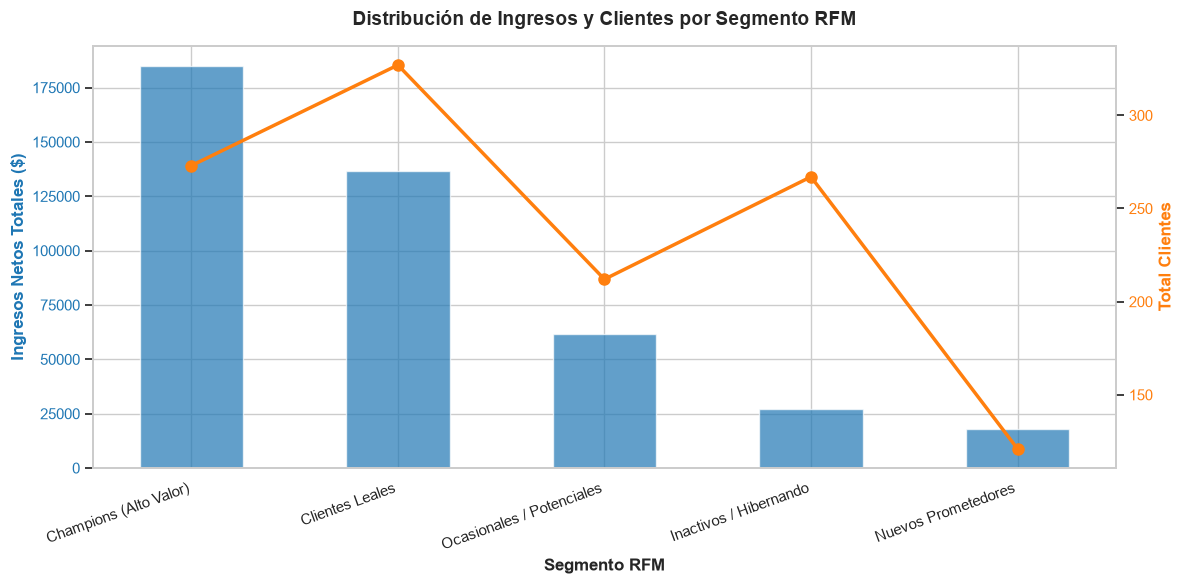

In [4]:
rfm_sql = """
WITH customer_summary AS (
    SELECT
        c.customer_key,
        c.customer_id,
        c.customer_name,
        c.country,
        c.segment AS market_segment,
        DATE_DIFF('day', MAX(d.full_date), DATE '2024-12-31') AS recency_days,
        COUNT(DISTINCT f.order_id) AS frequency_orders,
        ROUND(SUM(f.net_amount), 2) AS monetary_value,
        ROUND(SUM(f.margin_amount), 2) AS total_margin
    FROM fact_orders f
    JOIN dim_customers c ON f.customer_key = c.customer_key
    JOIN dim_date d ON f.order_date_key = d.date_key
    GROUP BY c.customer_key, c.customer_id, c.customer_name, c.country, c.segment
),
rfm_scoring AS (
    SELECT
        *,
        NTILE(4) OVER (ORDER BY recency_days DESC) AS r_score,
        NTILE(4) OVER (ORDER BY frequency_orders ASC) AS f_score,
        NTILE(4) OVER (ORDER BY monetary_value ASC) AS m_score
    FROM customer_summary
),
rfm_segmented AS (
    SELECT
        *,
        CASE
            WHEN r_score >= 3 AND f_score >= 3 AND m_score >= 3 THEN 'Champions (Alto Valor)'
            WHEN f_score >= 3 THEN 'Clientes Leales'
            WHEN r_score >= 3 AND f_score = 1 THEN 'Nuevos Prometedores'
            WHEN r_score <= 2 AND f_score >= 3 THEN 'En Riesgo de Fuga'
            WHEN r_score <= 2 AND f_score <= 2 AND m_score <= 2 THEN 'Inactivos / Hibernando'
            ELSE 'Ocasionales / Potenciales'
        END AS rfm_segment
    FROM rfm_scoring
)
SELECT
    rfm_segment,
    COUNT(*) AS total_customers,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 1) AS pct_customers,
    ROUND(AVG(recency_days), 0) AS avg_recency,
    ROUND(AVG(frequency_orders), 1) AS avg_orders,
    ROUND(AVG(monetary_value), 2) AS avg_spend,
    ROUND(SUM(monetary_value), 2) AS total_revenue,
    ROUND(SUM(total_margin), 2) AS total_profit
FROM rfm_segmented
GROUP BY rfm_segment
ORDER BY total_revenue DESC;
"""

df_rfm = con.execute(rfm_sql).fetchdf()
display(df_rfm)

# Gráfico de barras: Ingresos generados vs Cantidad de clientes por segmento
fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'tab:blue'
ax1.set_xlabel('Segmento RFM', fontsize=12, fontweight='bold')
ax1.set_ylabel('Ingresos Netos Totales ($)', color=color, fontsize=12, fontweight='bold')
bars = ax1.bar(df_rfm['rfm_segment'], df_rfm['total_revenue'], color=color, alpha=0.7, width=0.5)
ax1.tick_params(axis='y', labelcolor=color)
plt.xticks(rotation=20, ha='right')

# Eje secundario para número de clientes
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Total Clientes', color=color, fontsize=12, fontweight='bold')
line = ax2.plot(df_rfm['rfm_segment'], df_rfm['total_customers'], color=color, marker='o', linewidth=2.5, markersize=8)
ax2.tick_params(axis='y', labelcolor=color)
ax2.grid(False)

plt.title('Distribución de Ingresos y Clientes por Segmento RFM', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


---
## 📈 5. Análisis de Customer Lifetime Value (CLV) Acumulado
Con la función de ventana `SUM(...) OVER (PARTITION BY customer_key ORDER BY order_date)`, rastreamos la curva de valor acumulado en el tiempo para los clientes más valiosos.


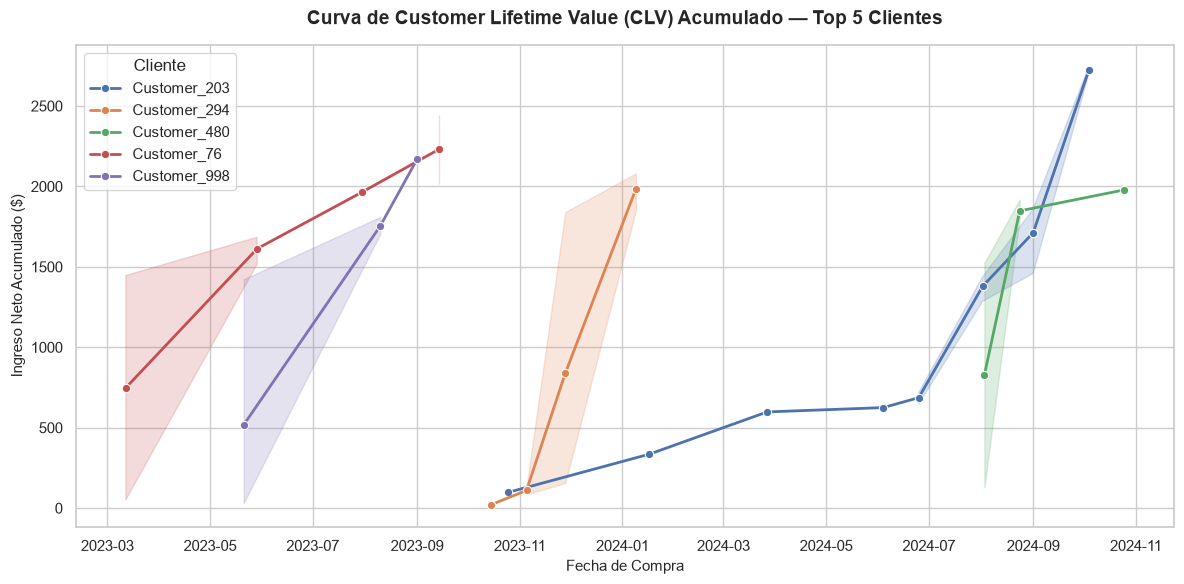

In [5]:
clv_sql = """
WITH customer_order_timeline AS (
    SELECT
        f.customer_key,
        c.customer_name,
        d.full_date AS order_date,
        f.net_amount,
        SUM(f.net_amount) OVER (
            PARTITION BY f.customer_key 
            ORDER BY d.full_date 
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        ) AS cumulative_clv
    FROM fact_orders f
    JOIN dim_customers c ON f.customer_key = c.customer_key
    JOIN dim_date d ON f.order_date_key = d.date_key
),
top_customers AS (
    SELECT customer_key
    FROM fact_orders
    GROUP BY customer_key
    ORDER BY SUM(net_amount) DESC
    LIMIT 5
)
SELECT
    t.customer_name,
    t.order_date,
    t.cumulative_clv
FROM customer_order_timeline t
JOIN top_customers tc ON t.customer_key = tc.customer_key
ORDER BY t.customer_name, t.order_date;
"""

df_clv = con.execute(clv_sql).fetchdf()

plt.figure(figsize=(12, 6))
sns.lineplot(data=df_clv, x='order_date', y='cumulative_clv', hue='customer_name', marker='o', linewidth=2)
plt.title("Curva de Customer Lifetime Value (CLV) Acumulado — Top 5 Clientes", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Fecha de Compra", fontsize=11)
plt.ylabel("Ingreso Neto Acumulado ($)", fontsize=11)
plt.legend(title="Cliente", frameon=True)
plt.tight_layout()
plt.show()

# Cerrar conexión
con.close()
